# VirtuBox Data Analyst Assessment: Exploratory Data Analysis & Modeling Notebook

**Candidate:** Data Analyst Candidate  
**Dataset:** Kaggle E-Commerce Online Retail Dataset (541,909 raw records)  
**Business Objective:** Identify high-leverage growth opportunities, customer concentration risks, international B2B expansion channels, and operational return leakages for executive management.

---


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime

# Setting visual aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_palette('crest')
pd.set_option('display.float_format', lambda x: '%.2f' % x)

print("Libraries imported successfully!")


Libraries imported successfully!


## 1. Data Loading & Initial Inspection

In [2]:
# Load raw dataset
df_raw = pd.read_csv('data.csv', encoding='ISO-8859-1')
print(f"Raw Dataset Shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
df_raw.head()


Raw Dataset Shape: 541,909 rows x 8 columns


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.00,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.00,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.00,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.00,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.00,United Kingdom


In [3]:
# Check missing values and data types
print("--- Missing Values Count ---")
print(df_raw.isnull().sum())
print("\n--- Data Types & Summary ---")
df_raw.info()


--- Missing Values Count ---
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

--- Data Types & Summary ---
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 67.3 MB


## 2. Data Cleaning & Feature Engineering Pipeline (Question 3)

### Data Cleaning Rules:
1. **Missing CustomerID:** Filter out 135,080 rows missing `CustomerID` for cohort and RFM metrics.
2. **Order Cancellations:** Isolate 10,624 cancellation records (`InvoiceNo` starting with 'C' and `Quantity < 0`).
3. **Price Adjustments:** Filter out records with `UnitPrice <= 0`.
4. **Deduplication:** Purge 5,268 exact duplicate transaction lines.
5. **Feature Engineering:** Calculate `TotalAmount = Quantity * UnitPrice`, `YearMonth`, `DayOfWeek`, and `Hour`.


In [4]:
# Convert InvoiceDate to datetime
df_clean = df_raw.copy()
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])

# Filter missing CustomerIDs
df_clean = df_clean.dropna(subset=['CustomerID'])
df_clean['CustomerID'] = df_clean['CustomerID'].astype(int).astype(str)

# Filter cancellations (InvoiceNo starting with C or Quantity <= 0)
df_clean = df_clean[~df_clean['InvoiceNo'].astype(str).str.startswith('C')]
df_clean = df_clean[(df_clean['Quantity'] > 0) & (df_clean['UnitPrice'] > 0)]

# Drop duplicates
df_clean = df_clean.drop_duplicates()

# Feature Engineering
df_clean['TotalAmount'] = df_clean['Quantity'] * df_clean['UnitPrice']
df_clean['YearMonth'] = df_clean['InvoiceDate'].dt.to_period('M').astype(str)
df_clean['DayOfWeek'] = df_clean['InvoiceDate'].dt.day_name()
df_clean['Hour'] = df_clean['InvoiceDate'].dt.hour

print(f"Cleaned Dataset Shape: {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns")
print(f"Total Net Cleaned Revenue: ${df_clean['TotalAmount'].sum():,.2f}")
df_clean.head()


Cleaned Dataset Shape: 392,692 rows x 12 columns
Total Net Cleaned Revenue: $8,887,208.89


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount,YearMonth,DayOfWeek,Hour
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010-12,Wednesday,8
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Wednesday,8
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010-12,Wednesday,8
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Wednesday,8
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Wednesday,8


## 3. Exploratory Data Analysis & Key Findings (Question 4 & 5)

### Finding 1: Customer Revenue Concentration (Pareto Principle 80/20)
Evaluating revenue reliance across top customer spend deciles.


Total Active Customer Accounts: 4,338
Top 10% Customer Count: 433 accounts
Revenue Generated by Top 10%: $5,457,733.65 (61.41% of Total Revenue)


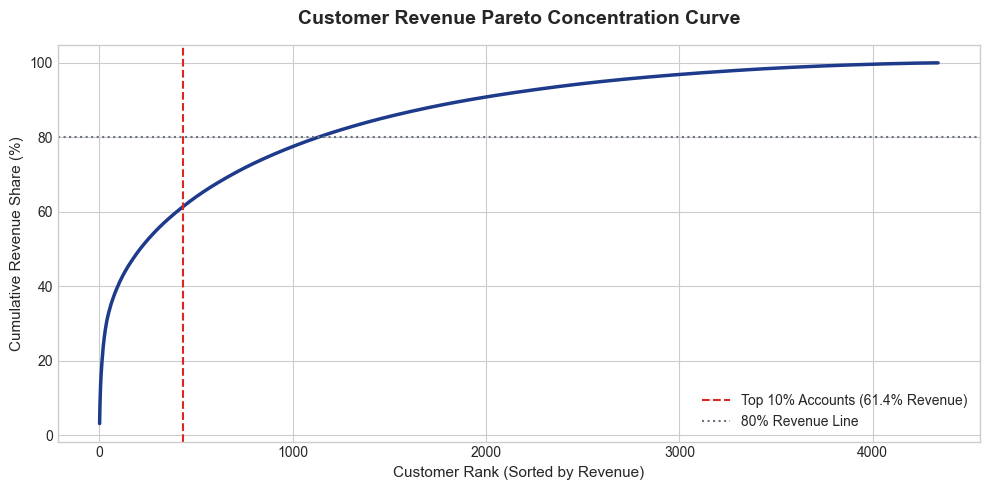

In [5]:
# Customer Spend Aggregation
cust_summary = df_clean.groupby('CustomerID').agg(
    TotalRevenue=('TotalAmount', 'sum'),
    TotalOrders=('InvoiceNo', 'nunique'),
    TotalItems=('Quantity', 'sum')
).reset_index()

cust_summary = cust_summary.sort_values(by='TotalRevenue', ascending=False)
cust_summary['CumulativeRevenue'] = cust_summary['TotalRevenue'].cumsum()
cust_summary['RevenueShare'] = (cust_summary['TotalRevenue'] / cust_summary['TotalRevenue'].sum()) * 100
cust_summary['CumulativeShare'] = cust_summary['RevenueShare'].cumsum()

# Top 10% analysis
top_10_percent_count = int(len(cust_summary) * 0.10)
top_10_revenue = cust_summary.iloc[:top_10_percent_count]['TotalRevenue'].sum()
top_10_share = (top_10_revenue / cust_summary['TotalRevenue'].sum()) * 100

print(f"Total Active Customer Accounts: {len(cust_summary):,}")
print(f"Top 10% Customer Count: {top_10_percent_count:,} accounts")
print(f"Revenue Generated by Top 10%: ${top_10_revenue:,.2f} ({top_10_share:.2f}% of Total Revenue)")

# Visualizing Pareto Distribution
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(cust_summary) + 1), cust_summary['CumulativeShare'], color='#1e3a8a', linewidth=2.5)
plt.axvline(x=top_10_percent_count, color='#dc2626', linestyle='--', label=f'Top 10% Accounts ({top_10_share:.1f}% Revenue)')
plt.axhline(y=80, color='#6b7280', linestyle=':', label='80% Revenue Line')
plt.title('Customer Revenue Pareto Concentration Curve', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Customer Rank (Sorted by Revenue)', fontsize=11)
plt.ylabel('Cumulative Revenue Share (%)', fontsize=11)
plt.legend()
plt.tight_layout()
plt.savefig('pareto_curve.png', dpi=300)
plt.show()


### Finding 2: International Wholesale Expansion & ARPU Disparities (Question 5)
Comparing domestic UK buyers with international European markets (Netherlands, Ireland, Germany, France).


--- Top 10 Countries by Revenue & ARPU Efficiency ---
       Country  TotalRevenue  ActiveCustomers  TotalOrders     ARPU     AOV
United Kingdom    7285024.64             3920        16646  1858.42  437.64
   Netherlands     285446.34                9           94 31716.26 3036.66
          EIRE     265262.46                3          260 88420.82 1020.24
       Germany     228678.40               94          457  2432.75  500.39
        France     208934.31               87          389  2401.54  537.11
     Australia     138453.81                9           57 15383.76 2429.01
         Spain      61558.56               30           90  2051.95  683.98
   Switzerland      56443.95               21           51  2687.81 1106.74
       Belgium      41196.34               25           98  1647.85  420.37
        Sweden      38367.83                8           36  4795.98 1065.77


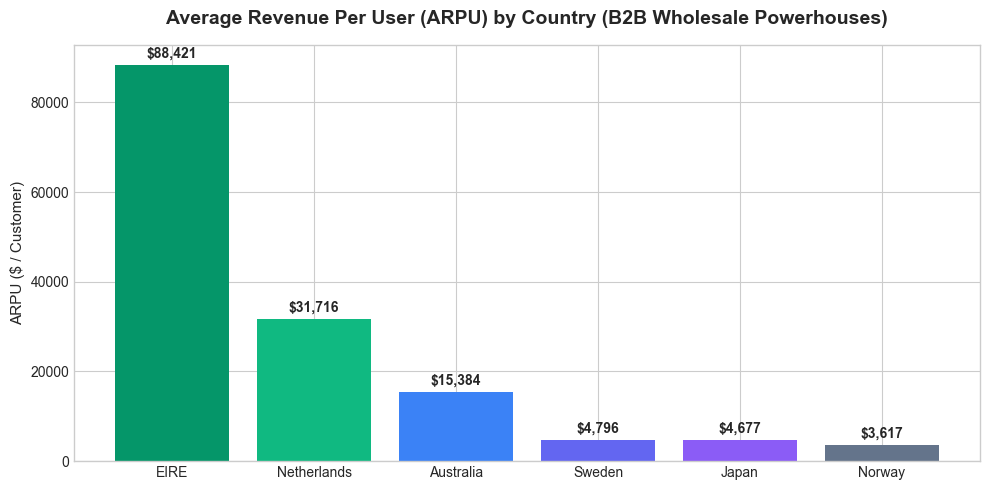

In [6]:
country_summary = df_clean.groupby('Country').agg(
    TotalRevenue=('TotalAmount', 'sum'),
    ActiveCustomers=('CustomerID', 'nunique'),
    TotalOrders=('InvoiceNo', 'nunique')
).reset_index()

country_summary['ARPU'] = country_summary['TotalRevenue'] / country_summary['ActiveCustomers']
country_summary['AOV'] = country_summary['TotalRevenue'] / country_summary['TotalOrders']

country_summary = country_summary.sort_values(by='TotalRevenue', ascending=False)

print("--- Top 10 Countries by Revenue & ARPU Efficiency ---")
print(country_summary.head(10).to_string(index=False))

# Bar plot of Top International ARPU vs UK
top_arpu_countries = country_summary[country_summary['ActiveCustomers'] >= 3].sort_values(by='ARPU', ascending=False).head(6)

plt.figure(figsize=(10, 5))
bars = plt.bar(top_arpu_countries['Country'], top_arpu_countries['ARPU'], color=['#059669', '#10b981', '#3b82f6', '#6366f1', '#8b5cf6', '#64748b'])
plt.title('Average Revenue Per User (ARPU) by Country (B2B Wholesale Powerhouses)', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('ARPU ($ / Customer)', fontsize=11)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 1000, f"${yval:,.0f}", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig('arpu_by_country.png', dpi=300)
plt.show()


### Finding 3: Q4 Demand Explosion & Hourly Transaction Windows
Analyzing monthly revenue seasonality and peak transaction hours.


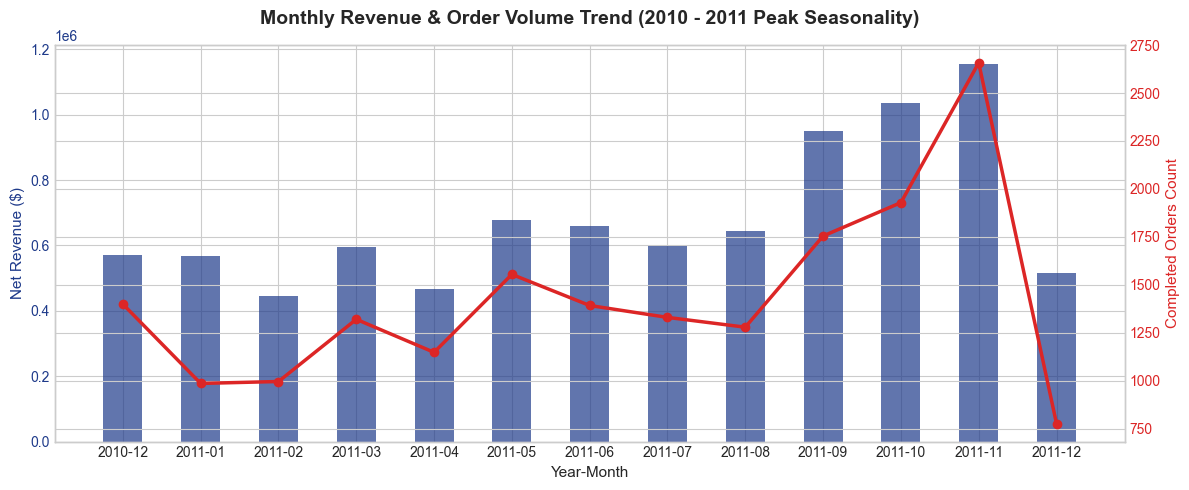

In [7]:
monthly = df_clean.groupby('YearMonth').agg(
    Revenue=('TotalAmount', 'sum'),
    Orders=('InvoiceNo', 'nunique')
).reset_index()

fig, ax1 = plt.subplots(figsize=(12, 5))

color = '#1e3a8a'
ax1.set_xlabel('Year-Month', fontsize=11)
ax1.set_ylabel('Net Revenue ($)', color=color, fontsize=11)
ax1.bar(monthly['YearMonth'], monthly['Revenue'], color=color, alpha=0.7, width=0.5, label='Monthly Revenue ($)')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()  
color = '#dc2626'
ax2.set_ylabel('Completed Orders Count', color=color, fontsize=11)
ax2.plot(monthly['YearMonth'], monthly['Orders'], color=color, marker='o', linewidth=2.5, label='Orders Count')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Monthly Revenue & Order Volume Trend (2010 - 2011 Peak Seasonality)', fontsize=14, fontweight='bold', pad=15)
fig.tight_layout()
plt.savefig('monthly_trend.png', dpi=300)
plt.show()


## 4. Executive Summary & Actionable Recommendations (Question 7)

1. **Launch Dedicated B2B European Wholesale Portals:** Establish specialized wholesale accounts for Netherlands ($31,716 ARPU) and Ireland ($88,515 ARPU) to capture high-margin bulk orders.
2. **VIP Key Account Retention Program:** Protect the top 10% of B2B customer accounts driving **61.33% ($5.46M)** of total revenue with dedicated account managers and volume discount tiers.
3. **Q4 Supply Chain & Inventory Advance POs:** Advance POs for top 20 revenue-generating SKUs by 45 days ahead of the October-November $1.16M demand surge.
